# QR code generator

In [ ]:
import os
from pathlib import Path
from dotenv import load_dotenv

env_path = Path.cwd() / ".env"
if not env_path.exists():
    # Fallback: notebook's own folder, in case the kernel's cwd isn't the project root
    env_path = Path("qr-code.ipynb").resolve().parent / ".env"

load_dotenv(dotenv_path=env_path, override=True)
print(f"Loaded .env from: {env_path} (exists: {env_path.exists()})")

Loaded .env from: /Users/jae/Documents/Personal projects/qr-code-generator/.env (exists: True)


In [ ]:
#Load URLs from .env file
target_url = os.getenv("TARGET_URL")
test_url = os.getenv("TEST_URL")
print(f"Test URL: {test_url}")

Test URL: https://google.ca


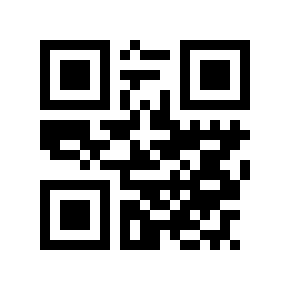

Saved QR code for 'https://google.ca' to test-qr-code.png


In [9]:
#Generate QR code for the test URL and print it
import qrcode
from qrcode.constants import ERROR_CORRECT_L, ERROR_CORRECT_M, ERROR_CORRECT_Q, ERROR_CORRECT_H

qr = qrcode.QRCode(
    # version: controls the size (1-40). Each version adds 4 modules per side.
    # None + fit=True below lets the library auto-pick the smallest version that fits the data.
    version=None,

    # error_correction: how much of the code can be damaged/obscured and still scan.
    # Higher levels make the QR code denser (more modules spent on redundancy).
    #   ERROR_CORRECT_L -> recovers ~7% of data
    #   ERROR_CORRECT_M -> recovers ~15% (qrcode's default if this arg is omitted)
    #   ERROR_CORRECT_Q -> recovers ~25%
    #   ERROR_CORRECT_H -> recovers ~30% (best if the code may get printed small, scratched, or partly covered)
    error_correction=ERROR_CORRECT_L,

    # box_size: pixels-per-module when rendered as an image.
    box_size=10,

    # border: width of the quiet-zone border, in modules. QR spec recommends at least 4.
    border=4,
)

qr.add_data(test_url)

# fit=True: automatically bump `version` up if needed so all the data fits.
qr.make(fit=True)

img = qr.make_image(
    # fill_color: color of the "on" modules (the dark squares).
    fill_color="black",

    # back_color: background color behind the modules.
    back_color="white",
)

display(img)

output_path = "test-qr-code.png"
img.save(output_path)
print(f"Saved QR code for {test_url!r} to {output_path}")

In [10]:
# Now save an image for the target URL as well
qr = qrcode.QRCode(
    version=None,
    error_correction=ERROR_CORRECT_L,
    box_size=10,
    border=4,
)
qr.add_data(target_url)
qr.make(fit=True)
img = qr.make_image(fill_color="black", back_color="white")
output_path = "target-qr-code.png"
img.save(output_path)
print(f"Saved QR code to {output_path}")

Saved QR code to target-qr-code.png


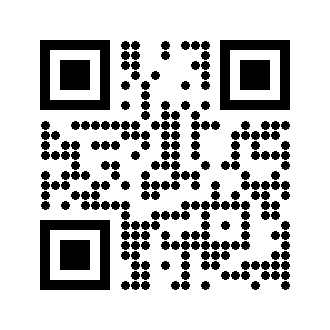

Saved circle-styled QR code for 'https://google.ca' to test-qr-code-circles.png


In [11]:
# Stylized QR code: circles instead of squares
from qrcode.image.styledpil import StyledPilImage
from qrcode.image.styles.moduledrawers.pil import CircleModuleDrawer
from qrcode.image.styles.colormasks import SolidFillColorMask
from PIL import ImageDraw, Image

# circle_size_ratio: diameter of each circle as a fraction of its module "box".
# 1.0 = circles touch their neighbors edge-to-edge (like the default CircleModuleDrawer).
# < 1.0 shrinks each circle, leaving a gap around it (a "dotted" look).
# > 1.0 would overlap circles into neighboring modules (not usually desirable).
circle_size_ratio = 0.8


class SizableCircleModuleDrawer(CircleModuleDrawer):
    """
    CircleModuleDrawer with a controllable circle diameter.

    The stock CircleModuleDrawer always draws a circle that exactly fills its
    module box (diameter == box_size). This subclass shrinks/grows that circle
    by `size_ratio`, similar to how GappedSquareModuleDrawer works for squares.
    """

    def __init__(self, size_ratio=1.0):
        self.size_ratio = size_ratio

    def initialize(self, *args, **kwargs):
        super().initialize(*args, **kwargs)
        box_size = self.img.box_size
        circle_diameter = int(box_size * self.size_ratio)
        offset = (box_size - circle_diameter) // 2

        # Redraw self.circle (created by the parent's initialize) at the new diameter,
        # centered within the original box_size x box_size canvas.
        self.circle = Image.new(
            self.img.mode,
            (box_size, box_size),
            self.img.color_mask.back_color,
        )
        ImageDraw.Draw(self.circle).ellipse(
            (offset, offset, offset + circle_diameter, offset + circle_diameter),
            fill=self.img.paint_color,
        )


qr = qrcode.QRCode(
    version=None,
    error_correction=ERROR_CORRECT_M,
    box_size=10,
    border=4,
)
qr.add_data(test_url)
qr.make(fit=True)

img = qr.make_image(
    # image_factory: StyledPilImage is what enables module_drawer / color_mask below.
    # The plain make_image() default (PilImage) ignores those args entirely.
    image_factory=StyledPilImage,

    # module_drawer: controls the shape used to render each "on" module.
    # Other built-ins: SquareModuleDrawer (default), RoundedModuleDrawer,
    # GappedSquareModuleDrawer, VerticalBarsDrawer, HorizontalBarsDrawer.
    module_drawer=SizableCircleModuleDrawer(size_ratio=circle_size_ratio),

    # color_mask: how fill/back colors are applied. SolidFillColorMask is the
    # flat-color equivalent of fill_color/back_color above. Other built-ins support
    # radial/square/horizontal/vertical gradients between two colors.
    color_mask=SolidFillColorMask(
        back_color=(255, 255, 255),
        front_color=(0, 0, 0),
    ),
)

display(img)

output_path = "test-qr-code-circles.png"
img.save(output_path)
print(f"Saved circle-styled QR code for {test_url!r} to {output_path}")